# 03 — Prédire les mécontents à l'atterrissage

Question : quels passagers approcher, sachant qu'on ne peut en approcher que 10 % ?

- Seulement ce que la compagnie connaît à l'atterrissage (`LANDING_COLS`) : aucune des 14 notes du questionnaire, rempli après le vol.
- Tout est mesuré sur `train.csv` par validation croisée à 5 blocs. `test.csv` n'est pas lu ici.
- Mesure : part de vrais insatisfaits parmi les 10 % de passagers les mieux classés, convertie en euros.

Le code est dans `src/rush3/prediction/` ; ce notebook le présente.

In [1]:
import pandas as pd
from sklearn.tree import export_text

from rush3.core.config import FIGURES
from rush3.core.contrats import ecrire_contrat
from rush3.core.donnees import load_train
from rush3.core.schema import CIBLE, LANDING_COLS
from rush3.prediction.metriques import CAPACITE
from rush3.prediction.modeles import MODELE_CHOISI, construire
from rush3.prediction.validation import comparer, essais_variables_sensibles
from rush3.core.economie import benefice_pour_1000, cout_des_erreurs

df = load_train()
print(df.shape, "- taux d'insatisfaits :", round(df[CIBLE].mean(), 3))
LANDING_COLS

(103904, 23) - taux d'insatisfaits : 0.567


['Customer Type',
 'Age',
 'Type of Travel',
 'Class',
 'Flight Distance',
 'Departure Delay in Minutes',
 'Arrival Delay in Minutes']

## 3.1 Ce qu'on sait à l'atterrissage

| Variable | Pourquoi elle est connue à l'atterrissage |
|---|---|
| Customer Type | programme de fidélité, dans le dossier client |
| Age | dossier de réservation |
| Type of Travel | motif du voyage, déclaré à la réservation |
| Class | billet |
| Flight Distance | vol |
| Departure / Arrival Delay | mesurés par la compagnie pendant le vol |

Exclues : les 14 notes (questionnaire rempli après le vol) et le genre (il n'apporte rien, voir 3.4).

## 3.2 Comparer les stratégies sans toucher à `test.csv`

Deux points de comparaison sans modèle (hasard, règle simple « voyage personnel ») puis trois modèles.
Pour chaque stratégie : précision moyenne sur les 5 blocs et écart entre blocs.

In [2]:
strategies = comparer(df)

tableau = pd.DataFrame(strategies).set_index("nom")[["precision_moyenne", "ecart_type"]]
tableau["bénéfice pour 1000 (€)"] = benefice_pour_1000(tableau["precision_moyenne"]).round(0)
regle = tableau.loc["Règle simple (voyage personnel)", "bénéfice pour 1000 (€)"]
tableau["gain sur la règle simple (€)"] = tableau["bénéfice pour 1000 (€)"] - regle
tableau

,precision_moyenne,ecart_type,bénéfice pour 1000 (€),gain sur la règle simple (€)
nom,,,,
Hasard,0.5667,0.0000,1667.0,-3298.0
Règle simple (voyage personnel),0.8965,0.0058,4965.0,0.0
Régression logistique,0.9367,0.0064,5367.0,402.0
Arbre de décision (4 niveaux),0.9551,0.0032,5551.0,586.0
Gradient boosting,0.9653,0.0049,5653.0,688.0


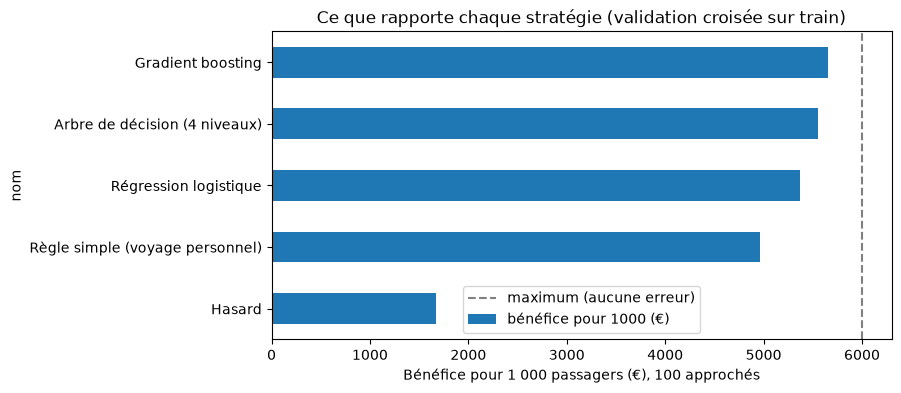

In [3]:
import matplotlib.pyplot as plt

FIGURES.mkdir(parents=True, exist_ok=True)
tableau["bénéfice pour 1000 (€)"].plot(kind="barh", figsize=(8, 4))
plt.axvline(6000, color="grey", linestyle="--", label="maximum (aucune erreur)")
plt.xlabel("Bénéfice pour 1 000 passagers (€), 100 approchés")
plt.title("Ce que rapporte chaque stratégie (validation croisée sur train)")
plt.legend()
plt.savefig(FIGURES / "03_benefice_par_strategie.png", bbox_inches="tight")
plt.show()

## 3.3 Lire l'arbre

L'arbre de décision se lit comme une suite de questions. Appris ici sur tout `train`, seulement pour l'afficher.

In [4]:
arbre = construire("Arbre de décision (4 niveaux)").fit(df[LANDING_COLS], df[CIBLE])
noms = arbre.named_steps["preparation"].get_feature_names_out().tolist()
print(export_text(arbre.named_steps["modele"], feature_names=noms))

|--- Class_Eco <= 0.50
|   |--- Type of Travel_Personal Travel <= 0.50
|   |   |--- Customer Type_disloyal Customer <= 0.50
|   |   |   |--- Class_Eco Plus <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Class_Eco Plus >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Customer Type_disloyal Customer >  0.50
|   |   |   |--- Age <= 24.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  24.50
|   |   |   |   |--- class: 1
|   |--- Type of Travel_Personal Travel >  0.50
|   |   |--- Arrival Delay in Minutes <= 5.50
|   |   |   |--- Class_Eco Plus <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Class_Eco Plus >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Arrival Delay in Minutes >  5.50
|   |   |   |--- Flight Distance <= 2710.50
|   |   |   |   |--- class: 1
|   |   |   |--- Flight Distance >  2710.50
|   |   |   |   |--- class: 1
|--- Class_Eco >  0.50
|   |--- Type of Travel_Personal Travel <= 0.50
|   |   |--- Customer Type_disloyal Customer <= 0.50
|   |   |  

## 3.4 Faut-il l'âge ? le genre ?

Pour la partie protection des données : ce qu'on perd sans l'âge, ce qu'on gagne avec le genre. Testé avec le modèle retenu (l'arbre) et avec le gradient boosting.

In [5]:
essais = essais_variables_sensibles(df, MODELE_CHOISI)
essais_gb = essais_variables_sensibles(df, "Gradient boosting")

sensibles = pd.DataFrame({
    MODELE_CHOISI: {e["nom"]: e["precision_moyenne"] for e in essais},
    "Gradient boosting": {e["nom"]: e["precision_moyenne"] for e in essais_gb},
})
pd.concat({
    "précision": sensibles,
    "bénéfice pour 1000 (€)": benefice_pour_1000(sensibles).round(0),
}, axis=1)

précision                    \
               Arbre de décision (4 niveaux) Gradient boosting   
modèle de base                        0.9551            0.9653   
sans l'âge                            0.9563            0.9553   
avec le genre                         0.9551            0.9653   

                      bénéfice pour 1000 (€)                    
               Arbre de décision (4 niveaux) Gradient boosting  
modèle de base                        5551.0            5653.0  
sans l'âge                            5563.0            5553.0  
avec le genre                         5551.0            5653.0

## 3.5 Le coût des erreurs du modèle choisi

Deux erreurs possibles : la fausse alerte (un passager satisfait approché : 40 € pour rien) et l'oubli (un insatisfait qu'on ne va pas voir).
Avec 10 % de capacité et environ 57 % d'insatisfaits, la plupart des insatisfaits seront forcément oubliés : c'est la limite de capacité, pas une faute du modèle.

In [6]:
print("Modèle choisi :", MODELE_CHOISI)
p = tableau.loc[MODELE_CHOISI, "precision_moyenne"]
erreurs = cout_des_erreurs(p, df[CIBLE].mean(), CAPACITE)
pd.Series(erreurs).round(0)

Modèle choisi : Arbre de décision (4 niveaux)


approches                       100.0
vrais_insatisfaits_approches     96.0
fausses_alertes                   4.0
cout_fausses_alertes            180.0
insatisfaits_oublies            471.0
dtype: float64

## 3.6 Choix du modèle

Trois critères : bénéfice, facilité d'explication, données personnelles nécessaires.

| | Règle simple | Arbre (4 niveaux) | Gradient boosting |
|---|---|---|---|
| Bénéfice pour 1 000 passagers | 4 965 € | 5 551 € | 5 653 € |
| Facile à expliquer | oui | oui, en une page (cellule 3.3) | non |
| Données nécessaires | motif du voyage | 6 informations (sans l'âge, voir 3.7) | 7 informations |

**Modèle retenu : l'arbre de décision (4 niveaux).** Il rapporte 586 € de plus que la règle simple pour 1 000 passagers et seulement 102 € de moins que le gradient boosting. Il se lit comme une suite de questions (classe Eco ? voyage personnel ? client fidèle ? retard à l'arrivée ? âge ?) que la directrice et l'équipe au sol peuvent comprendre et contester. Le gradient boosting gagne 102 € de plus mais reste une boîte noire : ce gain ne justifie pas de renoncer à l'explication.

Le choix est fixé dans `MODELE_CHOISI` (`src/rush3/prediction/modeles.py`) ; c'est lui que le test final évalue.

## 3.7 La version déployée : l'arbre sans l'âge

La section 3.4 montre que l'âge n'apporte rien à l'arbre. Par minimisation des données personnelles, la version déployée de l'arbre n'utilise donc pas l'âge (`construire_deploiement`). L'âge reste lu pour une seule chose : la règle « aucun mineur signalé » (partie protection des données).

Le contrôle final sur `test.csv` (notebook 04) a été fait avant cette décision, avec l'arbre à 7 informations. Il n'est pas relancé : le fichier de test ne s'utilise qu'une fois. Les chiffres ci-dessous comparent les versions sur `train.csv` uniquement.

In [7]:
from rush3.prediction.modeles import DEPLOIEMENT_COLS, construire_deploiement
from rush3.prediction.validation import evaluer_deploiement

deploiement = evaluer_deploiement(df)
tableau_deploiement = pd.DataFrame(deploiement).set_index("nom")
tableau_deploiement["bénéfice (€)"] = benefice_pour_1000(tableau_deploiement["precision_moyenne"]).round(0)
tableau_deploiement["bénéfice sans mineurs (€)"] = benefice_pour_1000(tableau_deploiement["precision_sans_mineurs"]).round(0)
tableau_deploiement

,precision_moyenne,precision_sans_mineurs,bénéfice (€),bénéfice sans mineurs (€)
nom,,,,
Arbre testé (7 informations),0.9551,0.9521,5551.0,5521.0
Arbre déployé (sans l'âge),0.9563,0.9494,5563.0,5494.0
Règle simple (voyage personnel),0.8965,0.8991,4965.0,4991.0


In [8]:
arbre_deploye = construire_deploiement().fit(df[DEPLOIEMENT_COLS], df[CIBLE])
noms = arbre_deploye.named_steps["preparation"].get_feature_names_out().tolist()
print(export_text(arbre_deploye.named_steps["modele"], feature_names=noms))

|--- Class_Eco <= 0.50
|   |--- Type of Travel_Personal Travel <= 0.50
|   |   |--- Customer Type_disloyal Customer <= 0.50
|   |   |   |--- Class_Eco Plus <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Class_Eco Plus >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Customer Type_disloyal Customer >  0.50
|   |   |   |--- Class_Eco Plus <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Class_Eco Plus >  0.50
|   |   |   |   |--- class: 1
|   |--- Type of Travel_Personal Travel >  0.50
|   |   |--- Arrival Delay in Minutes <= 5.50
|   |   |   |--- Class_Eco Plus <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Class_Eco Plus >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Arrival Delay in Minutes >  5.50
|   |   |   |--- Flight Distance <= 2710.50
|   |   |   |   |--- class: 1
|   |   |   |--- Flight Distance >  2710.50
|   |   |   |   |--- class: 1
|--- Class_Eco >  0.50
|   |--- Type of Travel_Personal Travel <= 0.50
|   |   |--- Customer Type_disloyal Customer

In [9]:
ecrire_contrat("03_comparaison_modeles", {
    "capacite": CAPACITE,
    "variables": LANDING_COLS,
    "strategies": strategies,
    "modele_choisi": MODELE_CHOISI,
    "deploiement": {"modele": MODELE_CHOISI, "variables": DEPLOIEMENT_COLS, "versions": deploiement},
})
ecrire_contrat("03_variables_sensibles", {
    "modele": MODELE_CHOISI,
    "essais": essais,
    "essais_gradient_boosting": essais_gb,
})
print("Contrats écrits dans results/")

Contrats écrits dans results/
